# Gate teleportation: a logical CX inside one code block

> **In short.**
> * **The question.** One code block can hold several logical qubits. A CX between logical qubits of *two* blocks is easy: a CX between each pair of matching physical qubits (transversal; L. Yeh's thesis, Lemma 6.38). A CX between two logical qubits c and t of the *same* block is not. L. Yeh's thesis (Proposition 6.41 and Eq. (6.42), after Gottesman 1997) does it with a second block, the *ancilla*: teleport c into the ancilla, move it to t's place there, do a transversal CX from the ancilla to the block, move it back, and teleport it back.
> * **Part 1, on logical qubits.** The protocol on four logical wires, as drawn at the top of Eq. (6.42), and the rewrite steps of that diagram: 33 spiders become a CX from c to t, with the ancilla's t left in $|0\rangle$, the last picture of Eq. (6.42).
> * **Parts 2 and 3, on physical qubits.** The same protocol on the toric code on a 2×2 torus, [[8,2,2]], with 17 qubits. Rewritten the same way, the whole circuit becomes the toric code's encoder after a CX; read through the code, it is the CX of Part 1, in every run.
> * **Parts 4 to 6.** The code after each step (question 1), what each step does to the logical qubits (questions 2 and 3), and fault tolerance: circuit distance 1 as in Eq. (6.42), 2 when c is measured twice.
> * **How to read the pictures.** Lines are qubits, time runs left to right; green and red dots are Z- and X-spiders, a blue edge is a Hadamard. A red dot with one wire on the left is $|0\rangle$, a green one $|+\rangle$; a phase such as `c[0]` means $\pi$ times that measurement result.
> * New to codes and ZX-diagrams? Start with [TInjectionWalkthrough.ipynb](TInjectionWalkthrough.ipynb), Part A.

In [1]:
%matplotlib inline
import sys
sys.path.insert(0, '..')
import pyzx as zx
from pyzx.circuit import Circuit
from pyzx.circuit.gates import CNOT, HAD, SWAP, Measurement, Reset
from pyzx.css import generate_css_encoder_graph
from pyzx.linalg import Mat2
from pyzx.utils import VertexType
from zxqec.qprogram import QProgram, ParityControlled, circuit_distance
from zxqec.codes import code_of
from zxqec.gpf import phases_modulo, reduce_gpf, to_gpf_steps
from zxqec.spacetime import draw_program

## 1. The protocol on logical qubits (Eq. (6.42))

Four lines, each one logical qubit: 0 is c and 1 is t of the data block, 2 is c and 3 is t of the ancilla, which starts with c in $|+\rangle$ and t in $|0\rangle$. Then, as in Eq. (6.42):

1. teleport c into the ancilla: a CX from each ancilla qubit to the same data qubit; measure c of the data block (result `c[0]`) and prepare it again in $|0\rangle$; if `c[0]` is 1, $X$ on the ancilla's c;
2. swap the ancilla's c and t (crossing wires);
3. the transversal CX again; the ancilla's t now holds c, so this is a CX from c to t of the data block;
4. swap back;
5. teleport c back: the transversal CX, then measure the ancilla's c in the X basis (result `c[1]`); if `c[1]` is 1, $Z$ on c of the data block.

deterministic: every run implements CNOT(0->1)


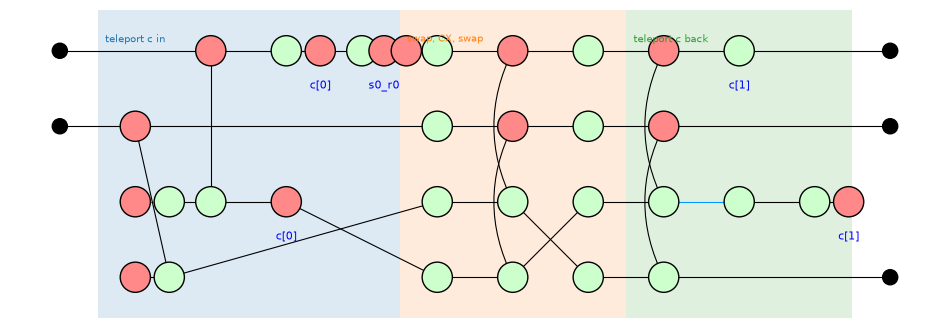

In [2]:
logical = QProgram(4, bits=2, initial_states={2: '+', 3: '0'})
c = Circuit(4, bit_amount=2)
for gate in [CNOT(2, 0), CNOT(3, 1), Measurement(0, 0), Reset(0), ParityControlled('X', 2, ['c[0]'])]:
    c.add_gate(gate)
logical.add_circuit(c, name='teleport c in')
logical.add_permutation([(2, 3)], cycles=True, name='swap c and t')
c = Circuit(4, bit_amount=2)
for gate in [CNOT(2, 0), CNOT(3, 1)]:
    c.add_gate(gate)
logical.add_circuit(c, name='transversal CX', physical=True)
logical.add_permutation([(2, 3)], cycles=True, name='swap back')
c = Circuit(4, bit_amount=2)
for gate in [CNOT(2, 0), CNOT(3, 1), HAD(2), Measurement(2, 1), ParityControlled('Z', 0, ['c[1]'])]:
    c.add_gate(gate)
logical.add_circuit(c, name='teleport c back')
steps = logical.group_stages([(0, 0, 'teleport c in'), (1, 3, 'swap, CX, swap'), (4, 4, 'teleport c back')])
print(logical.logical_action().verdict())
draw_program(logical, level=steps, show_time=False, labels=False, figsize=(12, 4))

### Where the diagram goes

The tool rewrites a diagram in five steps (`to_gpf_steps`); every picture below is the same map as the circuit, for every value of the results. Eq. (6.42) uses other rewrites in another order; it starts and ends at the same diagrams.

the diagram (33 spiders)


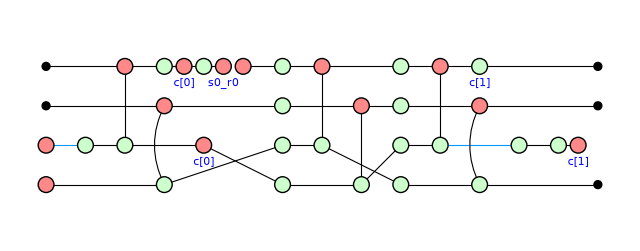

identity spiders removed, neighbours of the same colour fused (14 spiders)


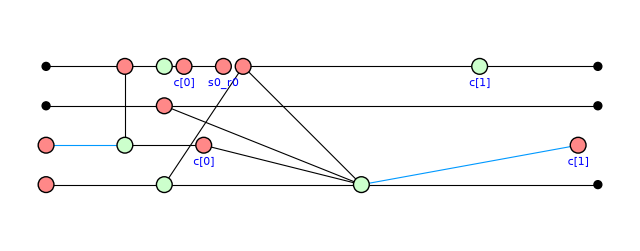

Hadamard edges pushed to the boundary wires, spiders fused (12 spiders)


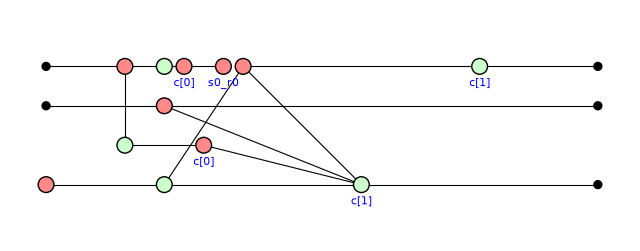

phases that are not Pauli moved onto gadgets (12 spiders)


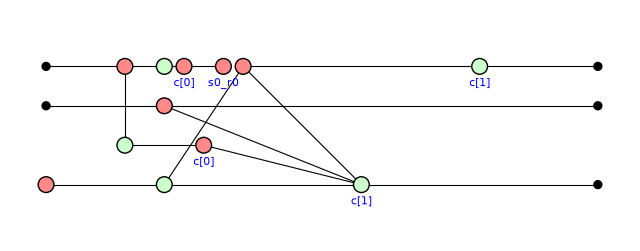

the bialgebra rule applied until two layers remain (4 spiders)


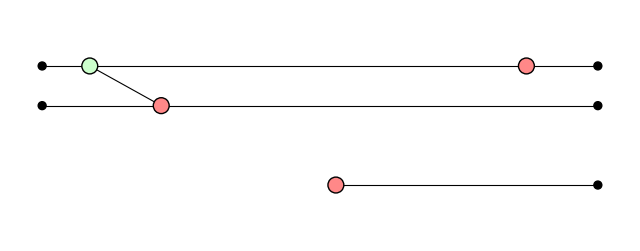

one Z-spider per input and one X-spider per output: the normal form (5 spiders)


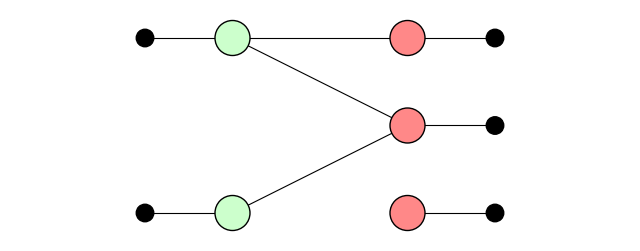

In [3]:
for what, h in to_gpf_steps(logical.quantum_graph()):
    print("{} ({} spiders)".format(what, sum(1 for v in h.vertices() if h.type(v) != VertexType.BOUNDARY)))
    display(zx.draw_matplotlib(h, figsize=(8, 3)))

* Step 1 fuses neighbouring spiders of the same colour. The swaps are only crossing wires and disappear. `s0_r0` is PyZX's variable for the state that the new preparation of c throws away.
* Step 2 moves the Hadamard edges to the boundary; step 3 changes nothing, as there is no $T$ gate.
* Step 4 (the bialgebra rule) leaves a Z-spider on c joined to an X-spider on t, which is a CX, and a red spider with one output on the ancilla's t, which is $|0\rangle$. The results `c[0]` and `c[1]` are gone: each correction cancels its result.
* Step 5 writes it with one Z-spider per input and one X-spider per output: the last picture of Eq. (6.42).

## 2. The same protocol on the toric code

A *code block* spreads logical qubits over many physical qubits. Here the block is the toric code on a 2×2 torus, [[8,2,2]]: eight qubits on the edges, two logical qubits. Qubit $2(2y+x)$ is the horizontal edge from the vertex $(x, y)$ and qubit $2(2y+x)+1$ the vertical one. The checks are $X$ on the four edges at a vertex (a *star*) and $Z$ on the four edges around a face (a *plaquette*). Logical qubit c has $X$ on the horizontal edges 0 and 4 (a loop around the torus) and $Z$ on 0 and 2; t has the same on the vertical edges: $X$ on 1 and 3, $Z$ on 1 and 5.

The data block is on qubits 0–7 (inputs c on qubit 2, t on qubit 5), the ancilla on 8–15, and qubit 16 (and 17) measures c. Each logical step of Part 1 becomes:

* a logical CX between the blocks: a CX from each ancilla qubit to the same data qubit;
* measuring c of the data block: its $Z$, on qubits 0 and 2, measured with helper 16; preparing it again in $|0\rangle$: $X$ of c (qubits 0 and 4) when `c[0]` is 1;
* $X$ on the ancilla's c: $X$ on qubits 8 and 12;
* the swap: in this code, a reordering of the qubits, the reflection of the torus across its diagonal, $(x, y) \to (y, x)$. It needs no gates: the next CX layer is wired to the reflected qubits (`add_permutation`, then the layer written on the wires, `physical=True`). A CX between c and t is not a reordering: of all 40 320 orderings of the eight qubits, those that keep the code give only the identity and the swap (`tests/test_teleportation.py`), which is why the protocol is needed;
* measuring the ancilla's c in the X basis: every ancilla qubit measured in the X basis (results `c[2]` to `c[9]`); its $X$ of c is on qubits 8 and 12, so its result is `c[2] + c[6]`;
* $Z$ on c of the data block: $Z$ on qubits 0 and 2.

The program is built twice: as in Eq. (6.42), with c measured once, and with c measured a second time on helper 17 (used in Part 6).

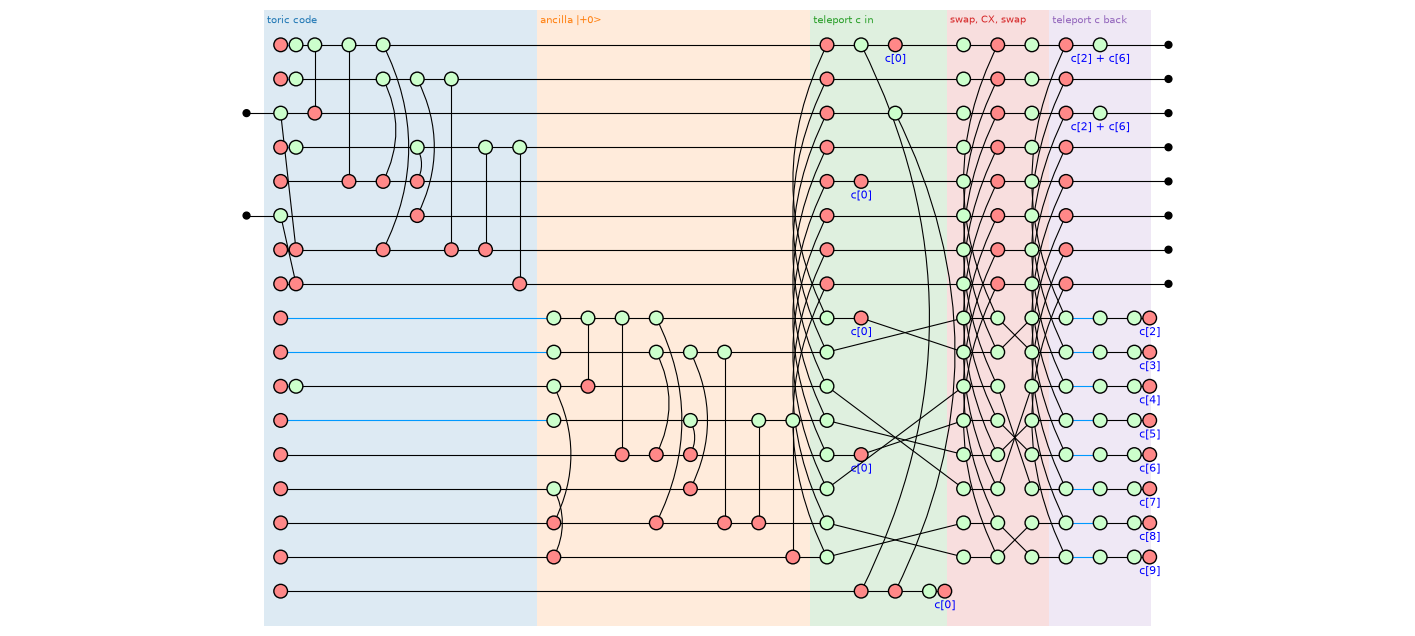

In [4]:
STARS = [[0, 1, 2, 5], [0, 2, 3, 7], [1, 4, 5, 6], [3, 4, 6, 7]]     # X on the four edges at a vertex
X_C, Z_C = [0, 4], [0, 2]                                           # logical qubit c
X_T = [1, 3]                                                        # the X of logical qubit t
# the encoder of the toric code, from the inputs on qubits 2 (c) and 5 (t)
TORIC = Circuit(8)
for gate in [CNOT(2, 6), CNOT(5, 7), HAD(0), CNOT(0, 2), CNOT(0, 4), CNOT(0, 6), HAD(1), CNOT(1, 4), CNOT(1, 5),
             CNOT(1, 6), HAD(3), CNOT(3, 4), CNOT(3, 6), CNOT(3, 7)]:
    TORIC.add_gate(gate)
# the reflection of the torus across its diagonal, (x, y) -> (y, x): it exchanges horizontal and vertical edges
REFLECT = [(0, 1), (2, 5), (3, 4), (6, 7)]

programs = {}
for twice in (False, True):
    n = 18 if twice else 17
    p = QProgram(n, bits=10, initial_states={**{q: '0' for q in range(n) if q not in (2, 5)}, 10: '+'})
    c = Circuit(n, bit_amount=10)
    c.add_circuit(TORIC, mask=list(range(8)), bit_mask=[])
    p.add_circuit(c, name='toric code')
    c = Circuit(n, bit_amount=10)
    c.add_circuit(TORIC, mask=list(range(8, 16)), bit_mask=[])          # from |+> on qubit 10 (c), |0> on 13 (t)
    p.add_circuit(c, name='ancilla |+0>')
    c = Circuit(n, bit_amount=10)
    for j in range(8):
        c.add_gate(CNOT(8 + j, j))
    for k in range(2 if twice else 1):
        for q in Z_C:
            c.add_gate(CNOT(q, 16 + k))
        c.add_gate(Measurement(16 + k, k))
    for q in X_C:
        c.add_gate(ParityControlled('X', 8 + q, ['c[0]']))
        c.add_gate(ParityControlled('X', q, ['c[0]']))
    p.add_circuit(c, name='teleport c in')
    p.add_permutation([(8 + a, 8 + b) for a, b in REFLECT], cycles=True, name='swap c and t')
    c = Circuit(n, bit_amount=10)
    for j in range(8):
        c.add_gate(CNOT(8 + j, j))
    p.add_circuit(c, name='transversal CX', physical=True)
    p.add_permutation([(8 + a, 8 + b) for a, b in REFLECT], cycles=True, name='swap back')
    c = Circuit(n, bit_amount=10)
    for j in range(8):
        c.add_gate(CNOT(8 + j, j))
    for j in range(8):
        c.add_gate(HAD(8 + j))
        c.add_gate(Measurement(8 + j, 2 + j))
    for q in Z_C:
        c.add_gate(ParityControlled('Z', q, ['c[%d]' % (2 + j) for j in X_C]))
    p.add_circuit(c, name='teleport c back')
    programs[twice] = p
once, p = programs[False], programs[True]
level = once.group_stages([(0, 0, 'toric code', 'encoder'), (1, 1, 'ancilla |+0>', 'state preparation'),
                           (2, 2, 'teleport c in', 'logical gate'), (3, 5, 'swap, CX, swap', 'transversal gate'),
                           (6, 6, 'teleport c back', 'logical gate')])
draw_program(once, level=level, show_time=False, labels=False, figsize=(18, 8))

The reflection maps $X$ of c (edges 0 and 4) to $X$ of t (edges 1 and 3), and stars to stars and plaquettes to plaquettes. Written as SWAP gates after the encoder, the tool finds the logical SWAP:

In [5]:
reflection = QProgram(8, initial_states={q: '0' for q in range(8) if q not in (2, 5)})
reflection.add_circuit(TORIC, name='toric code')
c = Circuit(8)
for a, b in REFLECT:
    c.add_gate(SWAP(a, b))
reflection.add_circuit(c, name='reflection')
print(reflection.logical_action().verdict())

deterministic: every run implements SWAP


## 3. Where the whole circuit goes

The same reduction as in Part 1, on the whole 17-qubit circuit (185 spiders), ends in the diagram below. Its phases depend on sums of results that are detectors, 0 in every run; written modulo the detectors (`phases_modulo`), every phase is 0. Each Z-spider is listed with the data qubits it is joined to.

phases as reduced: ['0', 'c[4] + c[8] + c[2] + c[6] + c[7] + c[3] + c[9] + c[5]', 'c[7] + c[3] + c[9] + c[5]']
modulo the detectors: ['0']
  Z-spider on input c joined to qubits [0, 1, 3, 4]
  Z-spider on input t joined to qubits [1, 3]
  Z-spider inside     joined to qubits [0, 2, 4, 6]
  Z-spider inside     joined to qubits [0, 2, 3, 7]
  Z-spider inside     joined to qubits [0, 1, 2, 5]


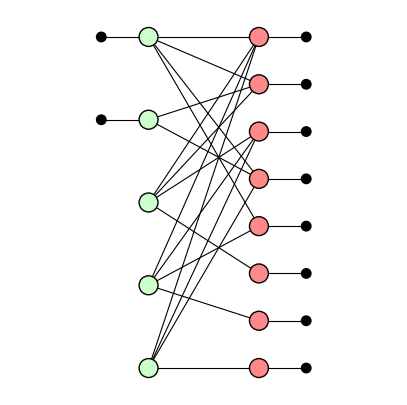

In [6]:
whole = reduce_gpf(once.quantum_graph())
print("phases as reduced:", sorted({str(whole.graph.phase(v)) for v in whole.graph.vertices()}))
nf = phases_modulo(whole.graph, whole.detectors)
print("modulo the detectors:", sorted({str(nf.phase(v)) for v in nf.vertices()}))
outputs = {next(iter(nf.neighbors(b))): j for j, b in enumerate(nf.outputs())}
inputs = {next(iter(nf.neighbors(b))): ('c' if j == 0 else 't') for j, b in enumerate(nf.inputs())}
for v in nf.vertices():
    if nf.type(v) == VertexType.Z:
        print("  Z-spider", "on input " + inputs[v] if v in inputs else "inside    ",
              "joined to qubits", sorted(outputs[w] for w in nf.neighbors(v) if w in outputs))
zx.draw_matplotlib(nf, figsize=(5, 5))

The three Z-spiders inside are each joined to four qubits that form a star or a product of two stars: three independent $X$ checks of the toric code. Input t is joined to qubits 1 and 3, its own $X$. Input c is joined to 0, 1, 3 and 4: $X$ of c *and* $X$ of t, because the CX copied c onto t. The encoder alone, for comparison:

In [7]:
alone = reduce_gpf(reflection.prefix_graph(0)).graph
outputs = {next(iter(alone.neighbors(b))): j for j, b in enumerate(alone.outputs())}
inputs = {next(iter(alone.neighbors(b))): ('c' if j == 0 else 't') for j, b in enumerate(alone.inputs())}
for v in alone.vertices():
    if alone.type(v) == VertexType.Z:
        print("  Z-spider", "on input " + inputs[v] if v in inputs else "inside    ",
              "joined to qubits", sorted(outputs[w] for w in alone.neighbors(v) if w in outputs))

  Z-spider on input c joined to qubits [0, 4]
  Z-spider on input t joined to qubits [1, 3]
  Z-spider inside     joined to qubits [1, 4, 5, 6]
  Z-spider inside     joined to qubits [0, 1, 2, 5]
  Z-spider inside     joined to qubits [1, 3, 5, 7]


The inputs differ only in that c is also joined to qubits 1 and 3 (the inside spiders are another choice of three checks). So the whole circuit is the toric code's encoder after a CX from c to t. Read through the code (the composite with the code's decoder, `logical_action`), it is that CX, the last picture of Part 1:

deterministic: every run implements CNOT(0->1)


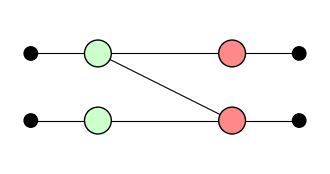

In [8]:
act = once.logical_action()
print(act.verdict())
zx.draw_matplotlib(phases_modulo(act.graph, act.detectors), figsize=(4, 2))

## 4. Question 1: which code after each step

Before the protocol: the toric code on qubits 0–7 (the last line compares it with the code built by PyZX from the stars and the two logical $X$, `pyzx.css`) and, on the ancilla, a state with no logical qubit (`[[8,0]]`): its c is $|+\rangle$ and its t is $|0\rangle$, so the $X$ of c and the $Z$ of t are stabilizers.

In [9]:
print(once.code_at(1))
toric, _ = generate_css_encoder_graph(Mat2([[int(q in s) for q in range(8)] for s in STARS]),
                                      Mat2([[int(q in X_C) for q in range(8)], [int(q in X_T) for q in range(8)]]), 'Z-X')
toric.auto_detect_io()
print("\nthe toric code:", once.code_at(1).restricted(list(range(8))).same_code_as(code_of(toric)))

[[8, 2, 2]] CSS code on qubits 0, 1, 2, 3, 4, 5, 6, 7
    stabilizer +XXXIIXII
    stabilizer +XIXXIIIX
    stabilizer +XIXIXIXI
    stabilizer +ZZIZZIII
    stabilizer +ZIZIZIZI
    stabilizer +ZIIIZZIZ
    logical X XIIIXIII   logical Z ZIZIIIII
    logical X IXIXIIII   logical Z IZIIIZII
[[8, 0, ?]] CSS code on qubits 8, 9, 10, 11, 12, 13, 14, 15
    stabilizer +XIIIXIII
    stabilizer +IIXIIIXI
    stabilizer +XXXIIXII
    stabilizer +XIXXIIIX
    stabilizer +IZIIIZII
    stabilizer +IIIZIIIZ
    stabilizer +ZZIZZIII
    stabilizer +ZIZIZIZI
fixed qubits: 16 in |0>

the toric code: True


After the first teleportation, each block holds one logical qubit. In the data block, $Z$ on qubits 0 and 2, the $Z$ of c, is now a stabilizer, so c is $|0\rangle$ there; its logical $X$ is on qubits 1 and 3, that of t. The ancilla's logical $X$ is on qubits 8 and 12, the $X$ of c: c has moved into the ancilla. Every sign is $+$: the corrections remove the dependence on `c[0]`.

In [10]:
print(once.code_at(2))

[[8, 1, 2]] CSS code on qubits 0, 1, 2, 3, 4, 5, 6, 7
    stabilizer +XXXIIXII
    stabilizer +XIXXIIIX
    stabilizer +XIXIXIXI
    stabilizer +ZIZIIIII
    stabilizer +IIIIZIZI
    stabilizer +ZZIZZIII
    stabilizer +ZIIIZZIZ
    logical X IXIXIIII   logical Z IZIIIZII
[[8, 1, 2]] CSS code on qubits 8, 9, 10, 11, 12, 13, 14, 15
    stabilizer +XXXIIXII
    stabilizer +XIXXIIIX
    stabilizer +XIXIXIXI
    stabilizer +IZIIIZII
    stabilizer +IIIZIIIZ
    stabilizer +ZZIZZIII
    stabilizer +ZIZIZIZI
    logical X XIIIXIII   logical Z ZIZIIIII


At the end, the ancilla is measured and the data block is the toric code again. One sign shows the sum `c[3] + c[5] + c[7] + c[9]` of the ancilla's results: that sum is one of the detectors, 0 in every run, so the sign is $+$.

In [11]:
print(once.code_at(6))
print("detectors:", *whole.detectors, sep="\n  ")
print("\nthe same code as before:", once.code_at(6).data().same_code_as(once.code_at(1).restricted(list(range(8)))))

[[8, 2, 2]] CSS code on qubits 0, 1, 2, 3, 4, 5, 6, 7
    stabilizer +IXIXIXIX
    stabilizer +IXIIXXXI
    stabilizer (-1)^(c[7] + c[3] + c[9] + c[5])XXXIIXII
    stabilizer +ZZIZZIII
    stabilizer +ZIZIZIZI
    stabilizer +ZIIIZZIZ
    logical X XIIIXIII   logical Z ZIZIIIII
    logical X IXIXIIII   logical Z IZIIIZII
detectors:
  c[7] + c[3] + c[9] + c[5]
  c[2] + c[7] + c[4] + c[3]
  c[6] + c[9] + c[5] + c[8]

the same code as before: True


## 5. Questions 2 and 3: what each step does

The level-up table, one row per block, with the checks of each block's role:

In [12]:
print(once.summary(level))

block              role               code before            code after             logical action  every run?  checks
0 toric code       encoder            [[1,1,1]] + [[1,1,1]]  [[8,2,2]]              I               yes         ok
1 ancilla |+0>     state preparation  [[8,2,2]]              [[8,2,2]] + [[8,0,?]]  I               yes         ok
2 teleport c in    logical gate       [[8,2,2]] + [[8,0,?]]  [[8,1,2]] + [[8,1,2]]  SWAP            yes         ok
3 swap, CX, swap   transversal gate   [[8,1,2]] + [[8,1,2]]  [[8,1,2]] + [[8,1,2]]  CNOT(1->0)      yes         ok
4 teleport c back  logical gate       [[8,1,2]] + [[8,1,2]]  [[8,2,2]]              SWAP            yes         ok

Block 0 'toric code' (encoder) -- stages 0
  code before: [[1,1,1]] on qubits 2; [[1,1,1]] on qubits 5
  code after:  [[8,2,2]] on qubits 0,1,2,3,4,5,6,7
  logical action: deterministic: every run implements I
  ok      encodes 2 logical qubit(s) into [[8,2,2]]
  ok      leaves the logical state unchange

The tool numbers the logical qubits of a code in the order of the qubits that carry them. Before the first teleportation, logical qubit 0 is c and 1 is t, both in the data block. After it, logical qubit 0 is t (in the data block, qubits 0–7) and 1 is c (in the ancilla, qubits 8–15). So moving c into the ancilla shows as SWAP; the CX between the swaps as CNOT(1→0), from c in the ancilla to t in the data block; and moving c back as SWAP. The middle block passes the transversal check: each of its CXs joins one ancilla qubit to one data qubit.

The ancilla's eight results are listed as *frame*: in the reduced diagram, a phase still depends on them, through the sums that Part 3 showed to be detectors. The result `c[0]` is *gauge*: random, and once corrected it affects nothing. One level up, the three blocks are one CX:

In [13]:
top = once.level_up(level, 2, 4, 'CX by gate teleportation', 'logical gate')
print(once.summary(top))

block                       role               code before            code after             logical action  every run?  checks
0 toric code                encoder            [[1,1,1]] + [[1,1,1]]  [[8,2,2]]              I               yes         ok
1 ancilla |+0>              state preparation  [[8,2,2]]              [[8,2,2]] + [[8,0,?]]  I               yes         ok
2 CX by gate teleportation  logical gate       [[8,2,2]] + [[8,0,?]]  [[8,2,2]]              CNOT(0->1)      yes         ok

Block 0 'toric code' (encoder) -- stages 0
  code before: [[1,1,1]] on qubits 2; [[1,1,1]] on qubits 5
  code after:  [[8,2,2]] on qubits 0,1,2,3,4,5,6,7
  logical action: deterministic: every run implements I
  ok      encodes 2 logical qubit(s) into [[8,2,2]]
  ok      leaves the logical state unchanged

Block 1 'ancilla |+0>' (state preparation) -- stages 1
  code before: [[8,2,2]] on qubits 0,1,2,3,4,5,6,7
  code after:  [[8,2,2]] on qubits 0,1,2,3,4,5,6,7; [[8,0,?]] on qubits 8,9,10,11,12,

## 6. Fault tolerance: circuit distance

The code has distance 2: an error on one of its qubits is always noticed. The *circuit* distance asks the same of faults anywhere in the gates: the smallest number of faults that changes the logical state while no detector notices (`circuit_distance`, with Stim and `codedistance`: `pip install zxqec[distance]`). It is measured here from the first teleportation to the end, for both logical qubits (`several_logicals=True`: every input logical prepared as $X$, then as $Z$, and the output logicals measured in every combination of $X$, $Y$ and $Z$).

As in Eq. (6.42), with c measured once, it is 1:

In [14]:
d = circuit_distance(once, 2, 6, several_logicals=True)
print("circuit distance:", d.distance)
print("a fault set:", *d.explain(), sep="\n  ")

circuit distance: 1
a fault set:
  stage 2: X16 before M 16 (flips its result)


One fault is enough: the result of the measurement of c is flipped. The corrections then apply $X$ of c to the ancilla's copy of c and to the data block, and no later measurement checks that result. Measuring c a second time (helper 17) and comparing the two results is a detector. The program is still a CX in every run, and the circuit distance is 2, the distance of the code, for every kind of fault:

In [15]:
print(p.logical_action().verdict())
for kind in ('full', 'Z', 'X'):
    print(kind, circuit_distance(p, 2, 6, kind=kind, several_logicals=True).distance)

deterministic: every run implements CNOT(0->1)


full 2


Z 2


X 2


## Summary

* On logical qubits (Part 1), the diagram of Eq. (6.42) rewrites to a CX from c to t, with the ancilla's t left in $|0\rangle$.
* On the toric code (Parts 2 and 3), the whole 17-qubit circuit rewrites to the toric code's encoder after that CX, and read through the code it is the CX, in every run.
* The tool follows c from the data block into the ancilla and back (Question 1); in its own numbering of the logical qubits, the steps are SWAP, CNOT(1→0) and SWAP (Questions 2 and 3).
* In the 2×2 toric code the swap inside the ancilla is a reordering of the qubits, so the protocol needs only transversal CX layers, measurements and Pauli corrections.
* With c measured once, as in Eq. (6.42), the circuit distance is 1; measured twice, 2.

What is not covered: the corrections are given here, not found by the tool; the rewrite steps are the tool's, not those of Eq. (6.42); the code is small (distance 2), so the circuit distance can be at most 2; and circuit distance counts the faults that go unnoticed, it does not decode.